In [5]:
from obspy.signal.trigger import plot_trigger, classic_sta_lta, trigger_onset#, energy_ratio, plot_trace
from obspy.signal.filter import envelope
from obspy import UTCDateTime, read
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import timezone
from obspy.signal.cross_correlation import correlate, xcorr_max
import os

Raw Data


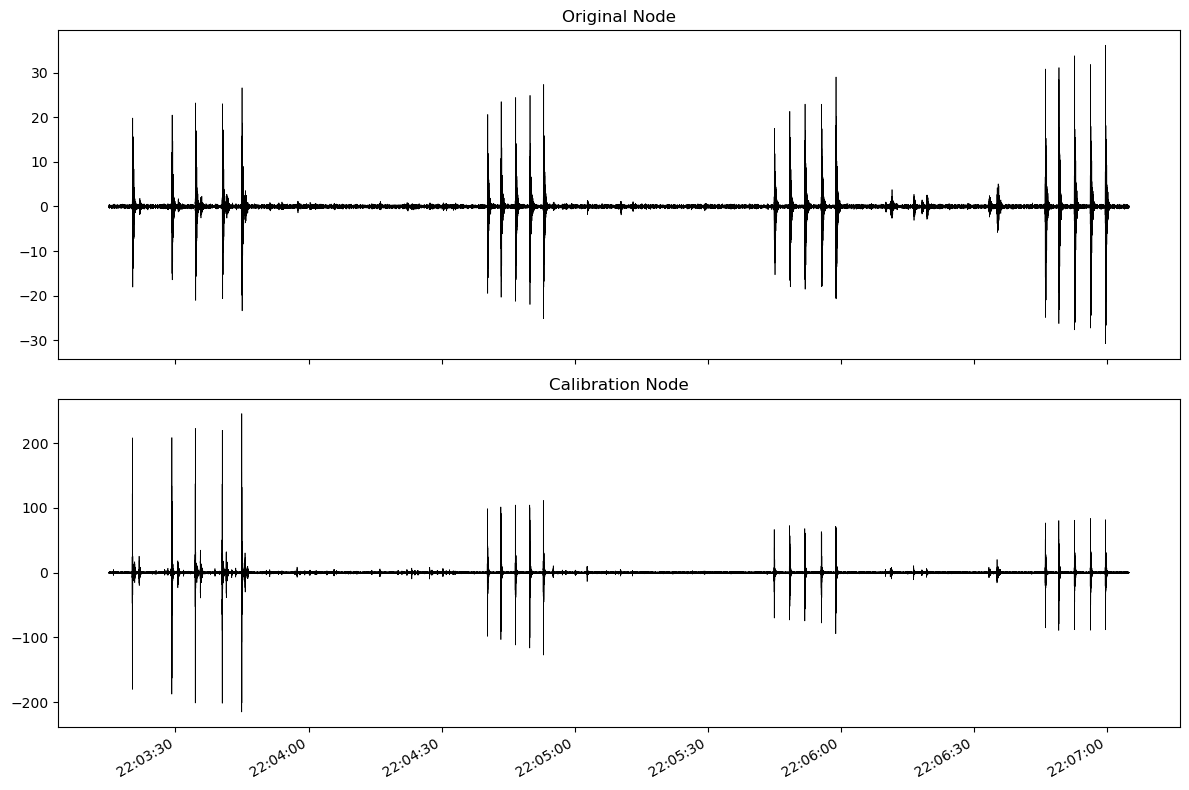

Blows occur within these time windows: user specified times


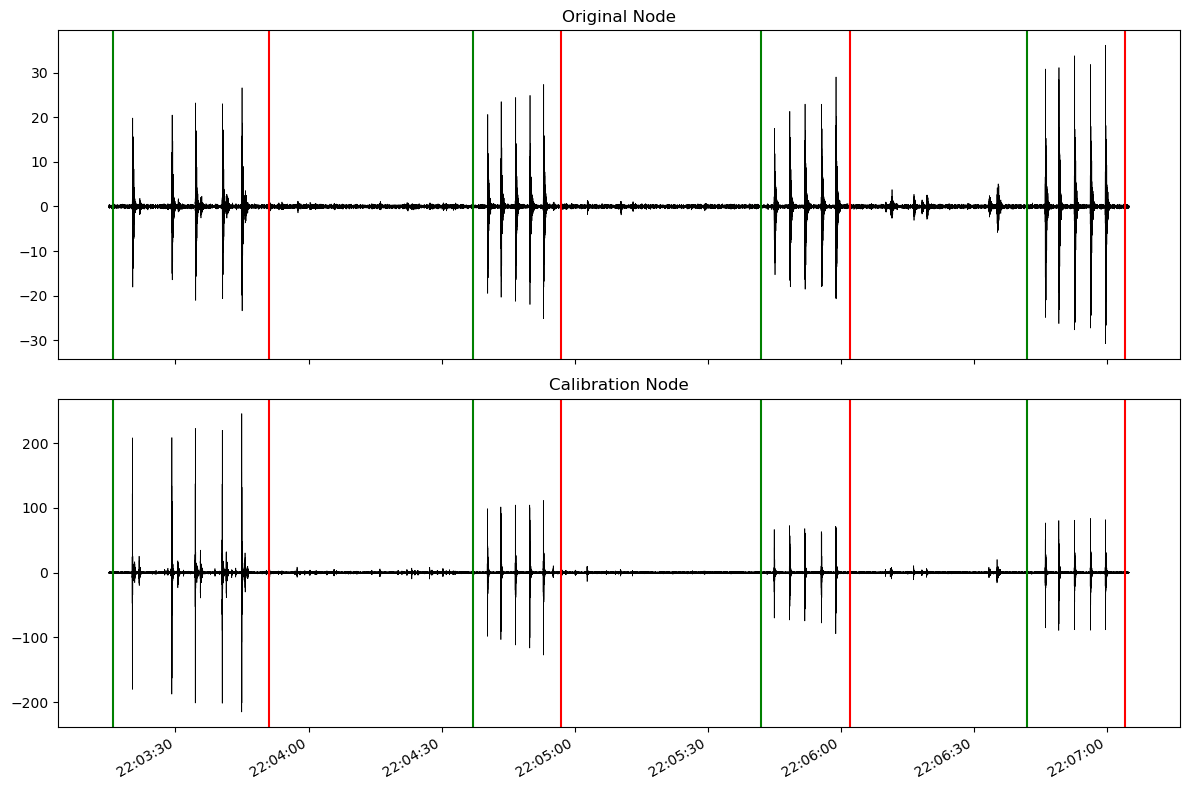

In [20]:
# load data

trace = {
    "og": read("D:/clipped_mseed/ZE.2511..GPZ_20251023214451_clipped.mseed"),
    "calib": read("D:/clipped_mseed/ZE.C2511..GPZ_20251023215340_clipped.mseed"),
}

blows = pd.DataFrame({
    "start": pd.to_datetime([
        "2025-10-23 22:03:16",
        "2025-10-23 22:04:37",
        "2025-10-23 22:05:42",
        "2025-10-23 22:06:42",
    ]).tz_localize("UTC"),

    "duration": [35, 20, 20, 22],
})

# position of each hammer-strike SET, measured from the OG node
source_x = [35, 33, 31, 29]

# total transect length
L = 44.2

# center frequencies
frequencies = [5, 10, 15, 20, 25, 30, 35, 40]

# plot and check raw data
# #plt.figure(figsize=(12,6))
# fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8))
# trace.plot(axes[0], trace["a"], title="Original Node")
# trace.plot(axes[1], trace["b"], title="Calibration Node")
# plt.tight_layout()
# plt.show()

def plot_stream_with_lines(ax, stream, vlines=None, title=None):
    """Plot all traces in a Stream on ax, with optional {color: [UTCDateTime,...]} vlines."""
    for tr in stream:
        ax.plot(tr.times("matplotlib"), tr.data, color="black", linewidth=0.5)
    ax.xaxis_date()
    if title:
        ax.set_title(str(title))
    if vlines:
        for color, times in vlines.items():
            for t in times:
                ax.axvline(t.matplotlib_date if isinstance(t, UTCDateTime) else t,
                            color=color)


print("Raw Data")
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8))
plot_stream_with_lines(axes[0], trace["og"], title="Original Node")
plot_stream_with_lines(axes[1], trace["calib"], title="Calibration Node")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## plot and check data with duration bars
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8))

blow_ends = blows["start"] + pd.to_timedelta(blows["duration"], unit="s")
green_lines = [UTCDateTime(t) for t in blows["start"]]
red_lines = [UTCDateTime(t) for t in blow_ends]

plot_stream_with_lines(axes[0], trace["og"], title="Original Node",
                        vlines={"green": green_lines, "red": red_lines})
plot_stream_with_lines(axes[1], trace["calib"], title="Calibration Node",
                        vlines={"green": green_lines, "red": red_lines})
print("Blows occur within these time windows: user specified times")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [27]:
# output settings
output_folder = "D:/seismic_picking_results/pick_plots"
os.makedirs(output_folder, exist_ok=True)

show_plots = False
save_plots = False

# 2. processing / picking settings

# sampling rate
fs = trace["og"][0].stats.sampling_rate

# STA/LTA parameters
sta_samples = 200 # int(sta_seconds*fs)
lta_samples = 3500 #int(lta_seconds*fs) (3.5 seconds at 1000 Hz, try to keep shorter than time between strikes)

sta_on = 4 # 4.5/2.5 not bad
sta_off = 3

# kurtosis parameters
kurtosis_window_samples = 200
kurt_amp_window_samples = 300

kurt_dur_min = 0.01
kurt_dur_max = 2.0

kurtosis_on = 17
kurtosis_off = 4

# cross-correlation maximum lag (samples)
lag_max = 1000

# processing buffer around each set
pre_buffer = 2#0.2
post_buffer = 2#0.4

# taper
taper_percentage = 0.02


# 3. node positions and distances

node_position = {
    "og": 0.0,
    "calib": L,
}

# check that each source position corresponds to a blow
if len(source_x) != len(blows):
    raise ValueError("source_x must contain one position per blow.")



# 4. HELPER FUNCTIONS

def get_utc_datetime(t):
    """Convert an ObsPy UTCDateTime to a timezone-aware datetime."""
    return t.datetime.replace(tzinfo=timezone.utc)


def get_trigger_picks(characteristic, fs, on, off):
    """
    Run trigger_onset on a characteristic function.
    Returns onset/offset sample indices.
    """
    picks = trigger_onset(
        characteristic,
        thres1=on,
        thres2=off
    )

    return picks


def calculate_rolling_kurtosis(signal, window_samples):
    """
    Calculate rolling excess kurtosis of a signal.

    scipy.stats.kurtosis(..., fisher=True) returns excess
    kurtosis, where a normal distribution has a value of 0.
    """

    series = pd.Series(signal)

    rolling_kurtosis = series.rolling(
        window=window_samples,
        center=True,
        min_periods=window_samples
    ).kurt()

    return rolling_kurtosis.to_numpy()


def robust_standardize(values):
    """
    Convert a characteristic function to a robust z-score
    using its median and median absolute deviation.
    """

    median = np.nanmedian(values)
    mad = np.nanmedian(np.abs(values - median))

    # MAD is scaled to estimate standard deviation
    robust_sigma = 1.4826 * mad

    if not np.isfinite(robust_sigma) or robust_sigma == 0:
        return np.zeros_like(values)

    return (values - median) / robust_sigma


def make_pick_rows(picks, method, characteristic, envelope_data, tr, fs, blow_id,
                   frequency, node, source_position, node_distance, core_start,
                   core_end, threshold_on, threshold_off):

    rows = []

    for pick_number, (onset, offset) in enumerate(picks, start=1):

        arrival_time = tr.stats.starttime + onset / fs

        # only retain arrivals inside the actual hammer-set interval
        if arrival_time < core_start or arrival_time > core_end:
            continue

        rows.append({
            "blow_id": blow_id,
            "node": node,
            "method": method,
            "frequency_hz": frequency,

            "arrival_time_utc": arrival_time.isoformat(),

            # characteristic-function value at estimated arrival
            "characteristic_value": characteristic[onset],

            # envelope amplitude at estimated arrival
            "envelope_amplitude_at_arrival": envelope_data[onset],

            # keep trigger interval for diagnostics
            "trigger_end_utc": (
                tr.stats.starttime + offset / fs
            ).isoformat(),

            "trigger_duration_s": (offset - onset) / fs,

            "source_x_from_og_m": source_position,
            "dx_m": node_distance,

            "threshold_on": threshold_on,
            "threshold_off": threshold_off,

            "sampling_rate_hz": fs,
            "status": "unreviewed"
        })

    return rows

def enforce_minimum_separation(picks, fs, min_separation_seconds=1.5):

    if len(picks) == 0:
        return picks

    min_samples = int(min_separation_seconds * fs)

    accepted = [picks[0]]

    for pick in picks[1:]:

        previous_onset = accepted[-1][0]
        current_onset = pick[0]

        if current_onset - previous_onset >= min_samples:
            accepted.append(pick)

    return np.array(accepted)

def plot_picks(tr_processed, env, sta_lta_cf, kurtosis_z, sta_picks,
               kurtosis_picks, node, frequency, blow_id, sta_on, sta_off,
               kurtosis_on, kurtosis_off, save_path=None):

    t = tr_processed.times("matplotlib")

    fig, axes = plt.subplots(
        4, 1,
        figsize=(15, 11),
        sharex=True
    )

    # 1. filtered waveform
    axes[0].plot(t, tr_processed.data, color="black", linewidth=0.6)
    axes[0].set_title(
        f"{node} | {frequency} Hz | {blow_id} — Filtered waveform"
    )
    axes[0].set_ylabel("Amplitude")

    # 2. Hilbert envelope
    axes[1].plot(t, env, color="black", linewidth=0.7)
    axes[1].set_ylabel("Envelope")

    # 3. STA/LTA characteristic function
    axes[2].plot(t, sta_lta_cf, color="black", linewidth=0.7)
    axes[2].axhline(sta_on, color="red", linestyle="--",
                    label=f"On threshold ({sta_on})")
    axes[2].axhline(sta_off, color="orange", linestyle=":",
                    label=f"Off threshold ({sta_off})")
    axes[2].set_ylabel("STA/LTA")
    axes[2].legend(loc="upper right")

    # 4. Kurtosis characteristic function
    axes[3].plot(t, kurtosis_z, color="black", linewidth=0.7)
    axes[3].axhline(kurtosis_on, color="red", linestyle="--",
                    label=f"On threshold ({kurtosis_on})")
    axes[3].axhline(kurtosis_off, color="orange", linestyle=":",
                    label=f"Off threshold ({kurtosis_off})")
    axes[3].set_ylabel("Kurtosis z-score")
    axes[3].legend(loc="upper right")

    # overlay onset picks on all four panels
    # filtered waveform, envelope, sta/lta funciton, kurtosis z-score
    for ax in axes:

        for i, (onset, offset) in enumerate(sta_picks):
            ax.axvline(
                t[onset],
                color="green",
                linestyle="--",
                linewidth=1,
                label="STA/LTA onset" if i == 0 else None
            )

        for i, (onset, offset) in enumerate(kurtosis_picks):
            ax.axvline(
                t[onset],
                color="blue",
                linestyle=":",
                linewidth=1,
                label="Kurtosis onset" if i == 0 else None
            )

    # Legend for onset lines
    axes[0].legend(loc="upper right")

    # UTC time formatting
    axes[-1].xaxis_date()
    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S", tz=timezone.utc)
    )
    axes[-1].set_xlabel("Time (UTC)")

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()
    plt.close(fig)
    
    
# 5. MAIN LOOP

results = {
    "og": [],
    "calib": [],
}

for blow_index, blow in blows.iterrows():

    blow_id = f"blow_{blow_index + 1:02d}"

    core_start = UTCDateTime(blow["start"].to_pydatetime())
    core_end = core_start + float(blow["duration"])

    # position of this hammer-strike set
    source_position = source_x[blow_index]

    print(f"\nProcessing {blow_id}")
    print(f"  Source position: {source_position} m from OG")

    for node in trace:

        # distance from this source to this node
        node_distance = abs(source_position - node_position[node])

        # include margin around the blow interval
        clip_start = core_start - pre_buffer
        clip_end = core_end + post_buffer

        # original stream contains one trace
        original_tr = trace[node][0]

        # clip original waveform
        clipped = original_tr.slice(
            starttime=clip_start,
            endtime=clip_end
        )

        if clipped.stats.npts == 0:
            print(f"  WARNING: No data for {node}, {blow_id}")
            continue

        fs = clipped.stats.sampling_rate

        print(f"  Node: {node}, dx = {node_distance:.1f} m")

        for frequency in frequencies:

            low = frequency - 1
            high = frequency + 1

            if low <= 0 or high >= fs / 2:
                print(f"    Skipping {frequency} Hz: invalid filter band")
                continue

            # A. detrend, demean, taper, and filter

            tr_processed = clipped.copy()

            # same preprocessing sequence as eseis lazy=TRUE
            tr_processed.detrend("demean")
            tr_processed.detrend("linear")

            # Butterworth bandpass
            tr_processed.filter(
                "bandpass",
                freqmin=low,
                freqmax=high,
                corners=2,
                zerophase=False
            )

            # eseis lazy=TRUE with p=0.02 applies the taper twice
            # not sure if twice is necessary ????
            tr_processed.taper(
                max_percentage=taper_percentage,
                type="cosine"
            )

            tr_processed.taper(
                max_percentage=taper_percentage,
                type="cosine"
            )


            # B. calculate envelope
            env = envelope(tr_processed.data)

            # C. STA/LTA on envelope

            # sta_samples = int(sta_seconds * fs)
            # lta_samples = int(lta_seconds * fs)

            if sta_samples < 1 or lta_samples <= sta_samples:
                raise ValueError("Check STA/LTA window settings.")

            sta_lta_cf = classic_sta_lta(
                env,
                sta_samples,
                lta_samples
            )

            sta_picks = get_trigger_picks(
                sta_lta_cf,
                fs,
                sta_on,
                sta_off
            )

            sta_picks = enforce_minimum_separation(sta_picks, fs, min_separation_seconds=1.5)#0.5)


            # D. rolling kurtosis on envelope --- see if rolling is the right idea of not

            # kurtosis_samples = max(3, int(kurtosis_window_seconds * fs))
            kurtosis_samples = kurtosis_window_samples
            
            rolling_kurt = calculate_rolling_kurtosis(env, kurtosis_samples)

            kurtosis_z = robust_standardize(rolling_kurt)

            # replace NaN values at the edges before triggering
            kurtosis_z = np.nan_to_num(
                kurtosis_z,
                nan=0.0,
                posinf=0.0,
                neginf=0.0
            )

            kurtosis_picks = get_trigger_picks(
                kurtosis_z,
                fs,
                kurtosis_on,
                kurtosis_off
            )

            kurtosis_picks = enforce_minimum_separation(kurtosis_picks, fs, min_separation_seconds=1.5)#0.5)
            
            # E. store pick results
            # if show_plots or save_plots:
            sta_rows = make_pick_rows(
                picks=sta_picks,
                method="sta_lta_envelope",
                characteristic=sta_lta_cf,
                envelope_data=env,
                tr=tr_processed,
                fs=fs,
                blow_id=blow_id,
                frequency=frequency,
                node=node,
                source_position=source_position,
                node_distance=node_distance,
                core_start=core_start,
                core_end=core_end,
                threshold_on=sta_on,
                threshold_off=sta_off
            )
            
            kurtosis_rows = make_pick_rows(
                picks=kurtosis_picks,
                method="kurtosis_envelope",
                characteristic=kurtosis_z,
                envelope_data=env,
                tr=tr_processed,
                fs=fs,
                blow_id=blow_id,
                frequency=frequency,
                node=node,
                source_position=source_position,
                node_distance=node_distance,
                core_start=core_start,
                core_end=core_end,
                threshold_on=kurtosis_on,
                threshold_off=kurtosis_off
            )
            
            results[node].extend(sta_rows)
            results[node].extend(kurtosis_rows)


            # F. create plot filename
            
            plot_file = None
            
            if save_plots:
                plot_file = os.path.join(output_folder, f"{node}_{blow_id}_{frequency}Hz_picks.png")
                
                print(repr(plot_file))
            # G. plot four-panel figure            
            if show_plots or save_plots:
            
                plot_picks(
                    tr_processed=tr_processed,
                    env=env,
                    sta_lta_cf=sta_lta_cf,
                    kurtosis_z=kurtosis_z,
                    sta_picks=sta_picks,
                    kurtosis_picks=kurtosis_picks,
                    node=node,
                    frequency=frequency,
                    blow_id=blow_id,
                    sta_on=sta_on,
                    sta_off=sta_off,
                    kurtosis_on=kurtosis_on,
                    kurtosis_off=kurtosis_off,
                    save_path=plot_file
                )


# 6. save one csv per node

for node in results:

    df_results = pd.DataFrame(results[node])

    # sort chronologically and group by blow, frequency, method
    df_results = df_results.sort_values(
        by=["blow_id", "frequency_hz", "method", "arrival_time_utc"],
        na_position="last"
    )

    output_file = os.path.join(
        output_folder,
        f"{node}_picks_unreviewed.csv"
    )

    df_results.to_csv(output_file, index=False)

    print(f"\nSaved {node} picks to:")
    print(output_file)

print("\nProcessing complete.")


Processing blow_01
  Source position: 35 m from OG
  Node: og, dx = 35.0 m
  Node: calib, dx = 9.2 m

Processing blow_02
  Source position: 33 m from OG
  Node: og, dx = 33.0 m
  Node: calib, dx = 11.2 m

Processing blow_03
  Source position: 31 m from OG
  Node: og, dx = 31.0 m
  Node: calib, dx = 13.2 m

Processing blow_04
  Source position: 29 m from OG
  Node: og, dx = 29.0 m
  Node: calib, dx = 15.2 m

Saved og picks to:
D:/seismic_picking_results/pick_plots\og_picks_unreviewed.csv

Saved calib picks to:
D:/seismic_picking_results/pick_plots\calib_picks_unreviewed.csv

Processing complete.
